In [1]:
import cv2
import matplotlib.pyplot as plt
import cvzone
import os
import random

In [4]:
images_path = '/home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/train/images'
labels_path = '/home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/train/labels'

Image_path is /home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/train/images/frame_99.png

Label_path is /home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/train/labels/frame_99.txt

Image_path is /home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/train/images/frame_8.png

Label_path is /home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/train/labels/frame_8.txt

Image_path is /home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/train/images/frame_144.png

Label_path is /home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/train/labels/frame_144.txt

Image_path is /home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/train/images/frame_453.png

Label_path is /home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/train/labels/frame_453.txt

Image_path is /home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Objec

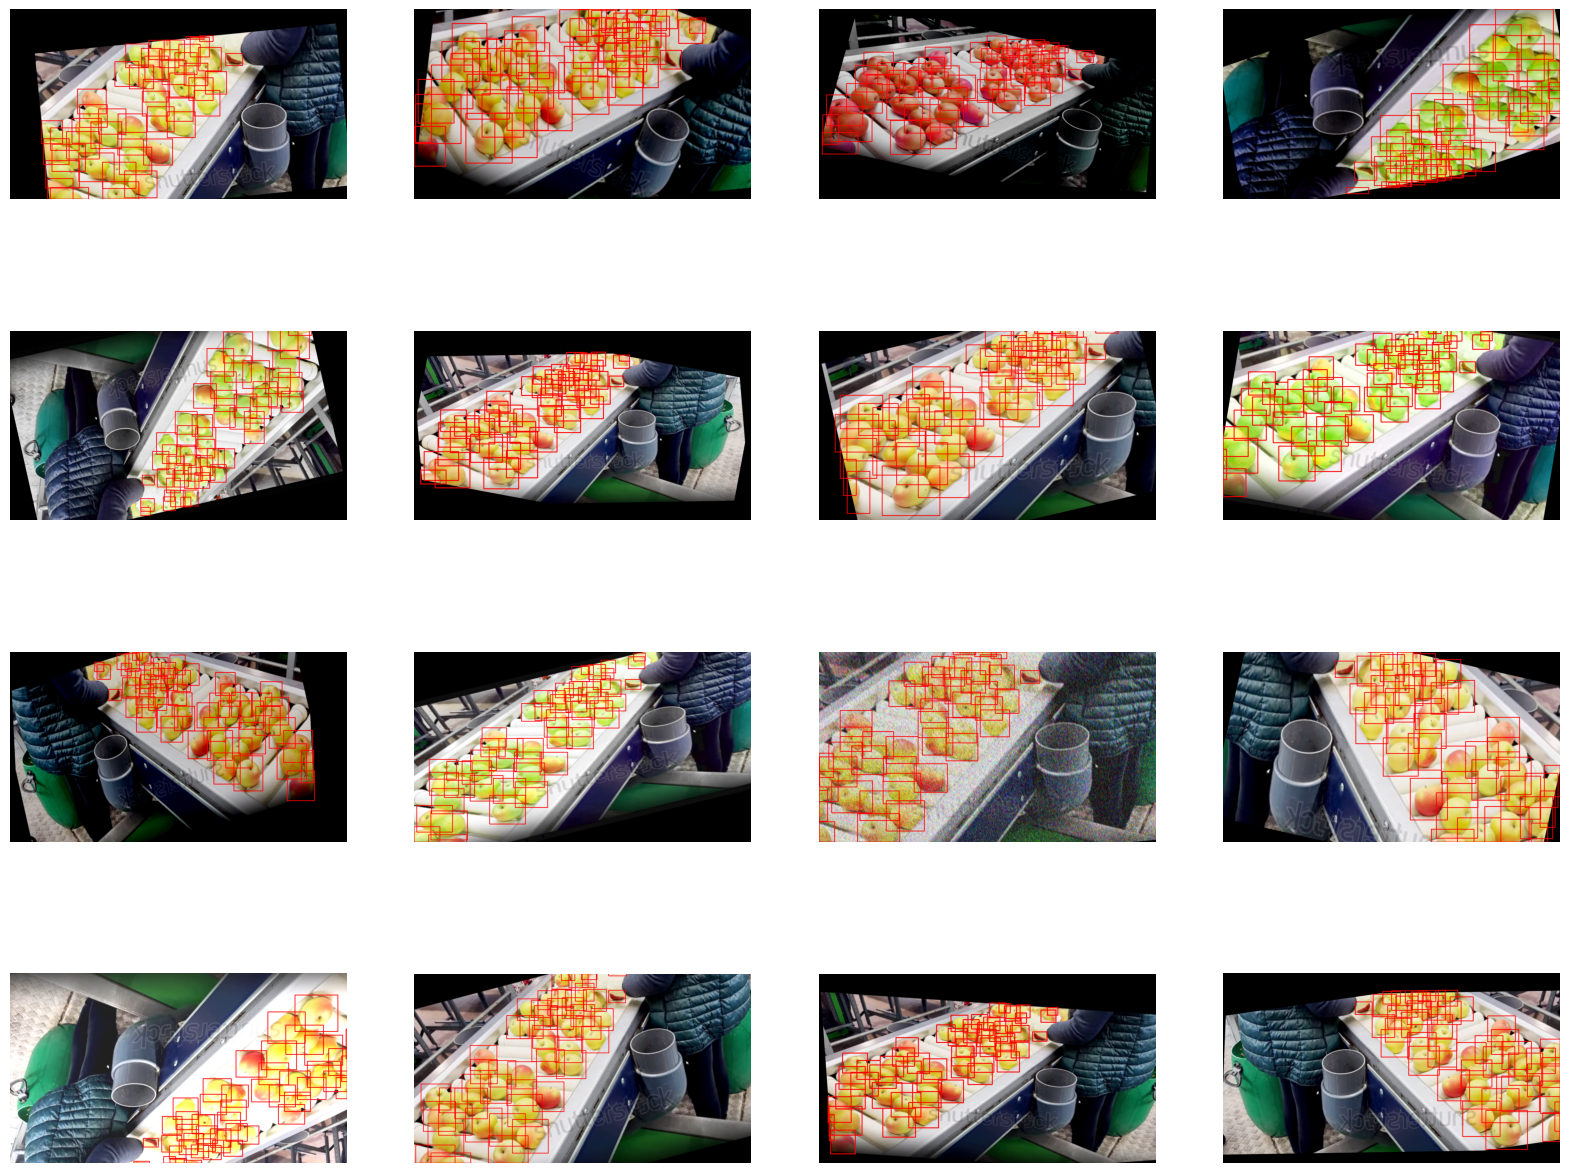

In [5]:
fig, ax = plt.subplots(4, 4, figsize=(20,16))
ax = ax.ravel()

for i in range(16):
    img_files = os.listdir(images_path)
    img_file_name = random.choice(img_files)

    img_path = os.path.join(images_path, img_file_name)
    label_path = os.path.join(labels_path, f"{img_file_name[:-4]}.txt")
    print(f"Image_path is {img_path}\n")
    print(f"Label_path is {label_path}\n")

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    height, width, _ = img.shape

    with open(label_path, 'r') as f:
        for line in f:
            data = line.strip().split()

            cls_id = int(data[0])

            # CORRECT YOLO FORMAT CONVERSION
            x_center = float(data[1]) * width
            y_center = float(data[2]) * height
            w_bbox = float(data[3]) * width
            h_bbox = float(data[4]) * height

            x1 = int(x_center - w_bbox / 2)
            y1 = int(y_center - h_bbox / 2)
            x2 = int(x_center + w_bbox / 2)
            y2 = int(y_center + h_bbox / 2)

            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)

    ax[i].imshow(img)
    ax[i].axis('off')